# Deep Neural Networks & PyTorch Fundamentals
### Deep Learning for Economics

Last week we built a **shallow neural network** (one hidden layer), derived **backpropagation** by hand in NumPy, and checked that PyTorch's autograd gives exactly the same gradients.

From now on we will let PyTorch do the backward pass for us. That frees us to go **deeper** and create very complex neaural network architectures with very little efforts.

This notebook is quite quite complicated and maybe overloaded, so no worries, if we cant finish it here, we can continue with it next week. Here i just want to emphasize the ease of PyTorch, applications of DL on economic problems, and also the idea that **Complex is NOT always the best**.

Spend some time and learn how to use PyTorch, its very powerful. The best resource I know for the moment is this amazing book ***Deep Learning with PyTorch* by Eli Stevens, Luca Antiga, and Thomas Viehmann**: https://www.oreilly.com/library/view/deep-learning-with/9781617295263/ 

You can run the code and follow the many projects step by step. Its not only PyTorch but also a very detailed manual of the mechanics of Deep Learning applied to diverse fields. You will thank me later!

**Today's plan**

| Part | Topic |
|---|---|
| 1 | PyTorch tensors: creation, shapes, broadcasting, the NumPy bridge, autograd |
| 2 | Our running example: learning a **CES production function** |
| 3 | Why go deep? Expressive power, activation functions, vanishing gradients, initialization |
| 4 | Building and training a feedforward network the PyTorch way (`nn.Module`, `DataLoader`, training loop) |
| 5 | Experiment: shallow vs. deep as the production function gets more curved |
| 6 | A first look at overfitting (teaser for next week) |
| 7 | Exercise: California housing prices |

In [1]:
# Load the necessary libraries
import copy
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split

In [2]:
# Make it consistent for all of us
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
# Activate colabs GPUs for speed (Its better to run this at the end since colab
# will not allow you GPUs forever)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.14.1+cpu | device: cpu


In [3]:
# A consistent, colorblind-friendly palette used for every plot in this notebook
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GRAY = "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})

# Part 1 — PyTorch Tensors

A **tensor** is PyTorch's version of a NumPy array, with two extra powers:
1. it can live on a **GPU**, and
2. it can **track the operations** applied to it, so gradients can be computed automatically (autograd).

For a more detailed and mathemarically beautiful explanation of Tensors watch this video on youtube: https://www.youtube.com/watch?v=f5liqUk0ZTw

## 1.1 Creating tensors

In [8]:
# from a Python list
a = torch.tensor([1.0, 2.0, 3.0])
# integers -> int64
B = torch.tensor([[1, 2], [3, 4]])

print("a =", a, "\ndtype:", a.dtype, "\nshape:", a.shape, "\nndim:", a.ndim)
print("-" * 20)
print("B =", B, "\ndtype:", B.dtype, "\nshape:", B.shape, "\nndim:", B.ndim)

a = tensor([1., 2., 3.]) 
dtype: torch.float32 
shape: torch.Size([3]) 
ndim: 1
--------------------
B = tensor([[1, 2],
        [3, 4]]) 
dtype: torch.int64 
shape: torch.Size([2, 2]) 
ndim: 2


In [11]:
# Multiple ways to intitiate tensors with different values/Distributions
print("zeros:\n", torch.zeros(2, 3))
print("ones:\n",  torch.ones(2, 3))
print("-" * 30)
# Create an Identity Matrix
print("identity:\n", torch.eye(3))
# Uniform Distribution
print("uniform U(0,1):\n", torch.rand(2, 3))
print("-" * 30)
# Standard Normal Distribution
print("standard normal:\n", torch.randn(2, 3))
print("-" * 30)
# Values between a and b with step c (range(a,b,c))
print("arange:", torch.arange(0, 10, 2))
print("-" * 30)
# Seme-distance values between a and b: np.linespace()
print("linspace:", torch.linspace(0, 1, 5))

zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
ones:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
------------------------------
identity:
 tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])
uniform U(0,1):
 tensor([[0.5779, 0.9040, 0.5547],
        [0.3423, 0.6343, 0.3644]])
------------------------------
standard normal:
 tensor([[-0.3514, -0.7906, -0.0915],
        [ 0.2352,  2.2440,  0.5817]])
------------------------------
arange: tensor([0, 2, 4, 6, 8])
------------------------------
linspace: tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


> **dtype matters.** Neural networks work with `float32` by default. If you build a tensor from integers you get `int64`, and mixing it with model weights raises an error. Use `torch.tensor(..., dtype=torch.float32)` or `.float()` when in doubt. This has to do with memory utitlization, and also the noisy nature of the NNs, and it is the current industry standard. Generally these are alla taken care of by PyTorch, but in case you run into trouble, it could be one of those hard to pick cases.

In [12]:
B_float = B.float()
print(B_float.dtype)

torch.float32


## 1.2 Indexing and reshaping

Indexing works like NumPy. The most important reshaping tools are `reshape`, `unsqueeze` / `squeeze` (add / remove a dimension of size 1) and `.T` (transpose).

**Convention used everywhere in deep learning:** a dataset is a 2-D tensor of shape **`(n_samples, n_features)`** — one row per observation, one column per variable, just like a regression design matrix.

In [18]:
x = torch.arange(12)
X = x.reshape(3, 4)

print("X =\n", X)
print("-" * 30)
print("X.T shape:", X.T.shape)
print("-" * 30)
print("second column:", X[:, 1])
print("-" * 30)
print("last row:", X[-1])
print("-" * 30)
print("elements > 5:", X[X > 5])

x= torch.Size([12])
------------------------------
X =
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
------------------------------
X.T shape: torch.Size([4, 3])
------------------------------
second column: tensor([1, 5, 9])
------------------------------
last row: tensor([ 8,  9, 10, 11])
------------------------------
elements > 5: tensor([ 6,  7,  8,  9, 10, 11])


In [19]:
v = torch.tensor([1.0, 2.0, 3.0])
print("\nv.shape :", v.shape, " <- a one dimensional tensor")
print("v.unsqueeze(0).shape :", v.unsqueeze(0).shape, " <- a row vector")
print("v.unsqueeze(1).shape :", v.unsqueeze(1).shape, " <- a column vector")


v.shape : torch.Size([3])  <- a one dimensional tensor
v.unsqueeze(0).shape : torch.Size([1, 3])  <- a row vector
v.unsqueeze(1).shape : torch.Size([3, 1])  <- a column vector


## 1.3 Operations and broadcasting

Arithmetic is element-wise; `@` is matrix multiplication; reductions (`sum`, `mean`, `std`, ...) take a `dim` argument.

**Broadcasting** lets you combine tensors of different shapes: dimensions of size 1 are automatically stretched. Basically, instead of forcing you to manually resize a smaller tensor to match a larger one, PyTorch virtually "stretches" the smaller tensor across the missing or size-1 dimensions during the calculation

An economics example: a **panel** of GDP growth for 5 countries × 10 years. We *build* the panel with broadcasting (country effect + year effect + noise), then apply the **within transformation** (subtract each country's mean), which is the fixed-effects estimator's first step.

In [31]:
torch.manual_seed(0)
countries = ["ALB", "ITA", "DEU", "GRC", "FRA"]
years = list(range(2015, 2025))

# shape (5, 1)
country_effect = torch.tensor([[3.5], [0.8], [1.2], [1.0], [1.1]])
# shape (1, 10)
print(country_effect)
print("Shape of Country Effect is: ", country_effect.shape)
print()

year_effect = torch.zeros(1, 10)
print("The shape of year_effect is: ", year_effect.shape)
print(year_effect)
print("\nAfter adding the shocks")
# a common shock in 2020 (COVID)
year_effect[0, 5] = -6.0
# rebound in 2021 (Post-COVID)
year_effect[0, 6] = 4.0
print(year_effect)

tensor([[3.5000],
        [0.8000],
        [1.2000],
        [1.0000],
        [1.1000]])
Shape of Country Effect is:  torch.Size([5, 1])

The shape of year_effect is:  torch.Size([1, 10])
tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

After adding the shocks
tensor([[ 0.,  0.,  0.,  0.,  0., -6.,  4.,  0.,  0.,  0.]])


In [32]:
# Dimensions we get:  (5,1) + (1,10) + (5,10) -> (5,10)
growth = country_effect + year_effect + 0.6 * torch.randn(5, 10)
print(growth)

tensor([[ 2.8245,  2.8086,  3.3497,  3.2397,  4.0092, -2.0848,  7.3104,  2.2309,
          3.6934,  2.7420],
        [ 1.0100,  0.9849,  0.8719,  1.5426,  1.4701, -5.3484,  3.9884, -0.2176,
          1.1400,  1.2761],
        [ 1.5593,  0.2669,  0.9952,  2.3118,  1.6501, -5.1513,  5.0960,  1.3101,
          2.0336,  2.1518],
        [ 1.5678,  0.4938,  0.6319,  1.0190,  1.6332, -4.8933,  4.8618,  0.7649,
          1.3260,  0.7629],
        [ 1.2233,  0.8298,  2.0126,  3.1463,  0.1813, -5.6405,  6.1918,  0.7691,
          0.3048,  1.2131]])


In [33]:
# Take the mean of each country over the years (5, 1)
country_mean = growth.mean(dim=1, keepdim=True)
# (5,10) - (5,1) -> (5,10)
demeaned = growth - country_mean
print("growth:", growth.shape, "| country_mean:", country_mean.shape, "| demeaned:", demeaned.shape)

growth: torch.Size([5, 10]) | country_mean: torch.Size([5, 1]) | demeaned: torch.Size([5, 10])


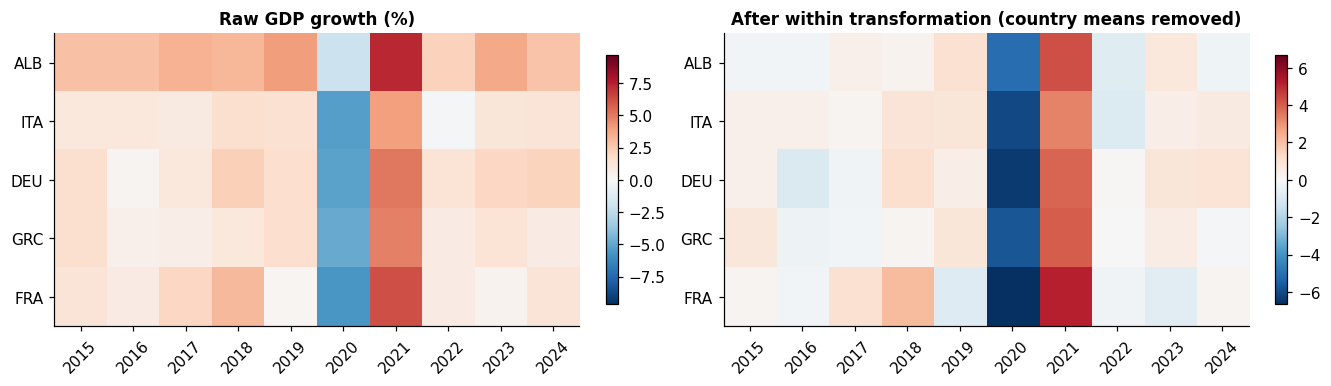

In [36]:
# Plot the whole thing in a heatmap
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True)
lim = demeaned.abs().max().item()
for ax, data, title, cmap, vmin, vmax in [
    (axes[0], growth,   "Raw GDP growth (%)", "RdBu_r", -lim - 3, lim + 3),
    (axes[1], demeaned, "After within transformation (country means removed)",
     "RdBu_r", -lim, lim),]:
    im = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(10), years, rotation=45)
    ax.set_yticks(range(5), countries)
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.85)
plt.show()

On the left, Albania's high average growth dominates its row. After subtracting each country's own mean (one line of broadcasting), only the **common 2020–21 shock** and idiosyncratic noise remain.

**Matrix algebra:** OLS in a few lines, $\hat\beta = (X^\top X)^{-1}X^\top y$.

In [37]:
torch.manual_seed(1)
n = 500
# years of schooling: add some noise (0,1)
educ = 8 + 10 * torch.rand(n)
# years of experience
exper = 30 * torch.rand(n)
log_wage = 1.0 + 0.08 * educ + 0.02 * exper + 0.3 * torch.randn(n)

# (500, 3) design matrix
X_ols = torch.stack([torch.ones(n), educ, exper], dim=1)
beta_hat = torch.linalg.solve(X_ols.T @ X_ols, X_ols.T @ log_wage)
print("true beta: [1.00, 0.08, 0.02]")
print("estimated beta:", beta_hat.numpy().round(3))

true beta: [1.00, 0.08, 0.02]
estimated beta: [0.93  0.085 0.018]


## 1.4 The NumPy bridge

`torch.from_numpy` and `.numpy()` convert back and forth **without copying**: both objects share the same memory. `torch.tensor(np_array)` always makes a copy. Use `.item()` to pull a single number out of a tensor.

In [38]:
arr = np.array([1.0, 2.0, 3.0])
# shares memory: remember list copying
t_shared = torch.from_numpy(arr)
# independent copy
t_copy = torch.tensor(arr)

arr[0] = 100.0
print("numpy array:", arr)
print("from_numpy :", t_shared, " <- changed too!")
print("torch.tensor:", t_copy, " <- unaffected")
print("a Python float:", t_copy.sum().item())

numpy array: [100.   2.   3.]
from_numpy : tensor([100.,   2.,   3.], dtype=torch.float64)  <- changed too!
torch.tensor: tensor([1., 2., 3.], dtype=torch.float64)  <- unaffected
a Python float: 6.0


## 1.5 Autograd recap: marginal products for free

Setting `requires_grad=True` tells PyTorch to record every operation. Calling `.backward()` on a scalar fills each leaf's `.grad` with the derivative.

Take a Cobb-Douglas production function $Y = K^{\alpha}L^{1-\alpha}$. Its marginal product of capital is $MPK = \partial Y/\partial K = \alpha\,Y/K$.

In [42]:
alpha = 0.33
K = torch.tensor(4.0, requires_grad=True)
L = torch.tensor(9.0, requires_grad=True)

# Define Y as the function above
Y = K**alpha * L**(1 - alpha)
Y.backward()

print(f"Y = {Y.item():.4f}")
# Calculate the derivatives and compare them with the analytic solutions
print(f"MPK  autograd: {K.grad.item():.6f}   analytic: {(alpha * Y / K).item():.6f}")
print(f"MPL  autograd: {L.grad.item():.6f}   analytic: {((1 - alpha) * Y / L).item():.6f}")

K value is:  tensor(4., requires_grad=True) | and L value is:  tensor(9., requires_grad=True)
Y = 6.8869
MPK  autograd: 0.568167   analytic: 0.568167
MPL  autograd: 0.512690   analytic: 0.512690


For a whole **vector** of capital values, call `.backward()` on `Y.sum()`. Each $Y_i$ depends only on its own $K_i$, so $\partial(\sum_j Y_j)/\partial K_i = \partial Y_i/\partial K_i$: one backward pass gives the MPK at every point.

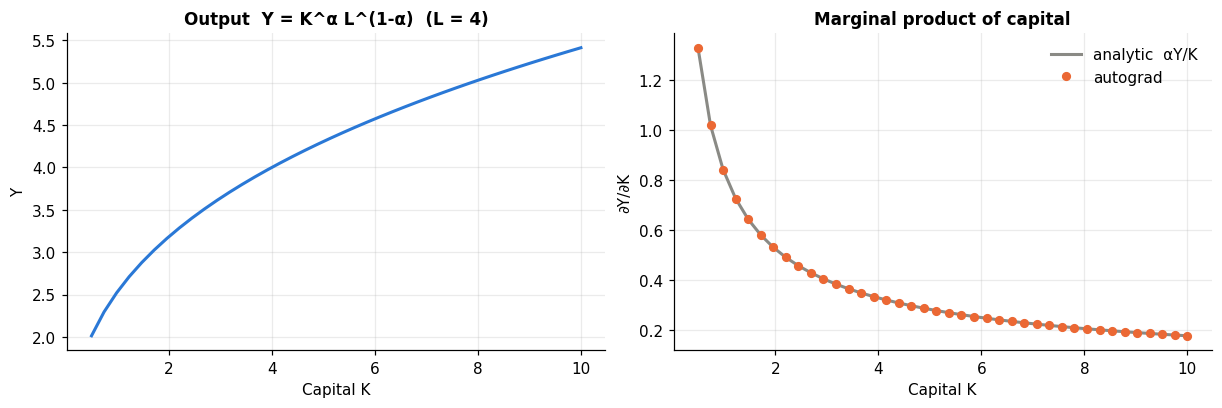

In [43]:
K_grid = torch.linspace(0.5, 10, 40, requires_grad=True)
L_fixed = 4.0
Y_grid = K_grid**alpha * L_fixed**(1 - alpha)
Y_grid.sum().backward()

mpk_autograd = K_grid.grad
# no tracking needed for the analytic formula
with torch.no_grad():
    mpk_analytic = alpha * Y_grid / K_grid
# .detach() before .numpy() for tracked tensors
Kn = K_grid.detach().numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].plot(Kn, Y_grid.detach().numpy(), color=COLORS[0])
axes[0].set(title="Output  Y = K^α L^(1-α)  (L = 4)", xlabel="Capital K", ylabel="Y")
axes[1].plot(Kn, mpk_analytic.numpy(), color=GRAY, label="analytic  αY/K")
axes[1].plot(Kn, mpk_autograd.numpy(), "o", ms=5, color=COLORS[1], label="autograd")
axes[1].set(title="Marginal product of capital", xlabel="Capital K", ylabel="∂Y/∂K")
axes[1].legend()
plt.show()

Three autograd habits worth knowing:
- **Gradients accumulate.** Calling `.backward()` twice *adds* to `.grad`. That's why training loops call `optimizer.zero_grad()` every step.
- **`torch.no_grad()`** switches tracking off (evaluation, plotting, manual updates).
- **`.detach()`** returns a tensor cut off from the graph; required before `.numpy()` on a tracked tensor.

In [46]:
w = torch.tensor(2.0, requires_grad=True)
for i in range(3):
    (w**2).backward()
    print(f"after backward #{i + 1}: w.grad = {w.grad.item()}",
          f"(true derivative is 4.0)")
w.grad.zero_()
print("after zero_():", w.grad.item())

after backward #1: w.grad = 4.0 (true derivative is 4.0)
after backward #2: w.grad = 8.0 (true derivative is 4.0)
after backward #3: w.grad = 12.0 (true derivative is 4.0)
after zero_(): 0.0


# Part 2 — Running Example: a CES Production Function

$$
Y = A\left[\alpha K^{\rho} + (1-\alpha)L^{\rho}\right]^{1/\rho},
\qquad \sigma = \frac{1}{1-\rho}
$$

$\sigma$ is the **elasticity of substitution** between capital and labor. The single parameter $\rho$ moves us across a whole family of technologies:

| $\rho$ | $\sigma$ | Technology | Shape |
|---|---|---|---|
| $\to 1$ | $\to\infty$ | perfect substitutes | almost a plane (easy) |
| $0$ | $1$ | Cobb-Douglas | smooth curvature |
| $-2$ | $1/3$ | strong complements | pronounced curvature |
| $\to -\infty$ | $\to 0$ | Leontief $\min(K, L)$ | a sharp **kink** |

That makes CES a perfect testbed: **we know the true function**, so we can see exactly what the network learns, and we can **dial the difficulty** with $\rho$.

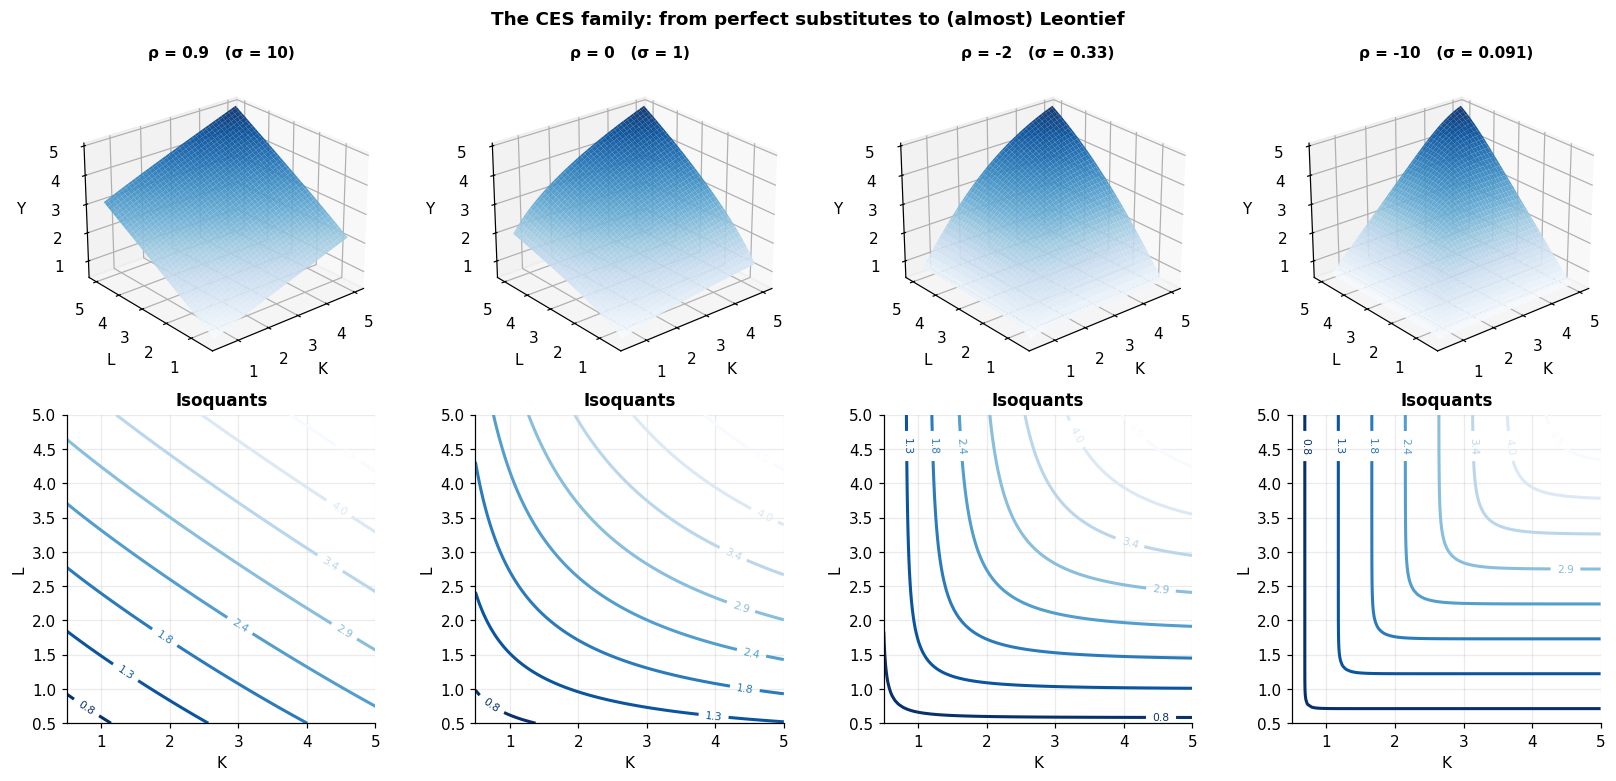

In [47]:
ALPHA, A_TFP = 0.4, 1.0

def ces(K, L, rho, alpha=ALPHA, A=A_TFP):
    # Works on NumPy arrays and on torch tensors (only uses arithmetic operators).
    if abs(rho) < 1e-8:
        # Cobb-Douglas limit
        return A * K**alpha * L**(1 - alpha)
    return A * (alpha * K**rho + (1 - alpha) * L**rho) ** (1 / rho)

K_LO, K_HI = 0.5, 5.0
RHOS = [0.9, 0.0, -2.0, -10.0]
RHO_LABELS = {r: f"ρ = {r:g}   (σ = {1 / (1 - r):.2g})" for r in RHOS}

kk, ll = np.meshgrid(np.linspace(K_LO, K_HI, 80), np.linspace(K_LO, K_HI, 80))

fig = plt.figure(figsize=(15, 7.2))
for j, rho in enumerate(RHOS):
    yy = ces(kk, ll, rho)
    ax = fig.add_subplot(2, 4, j + 1, projection="3d")
    ax.plot_surface(kk, ll, yy, cmap="Blues", linewidth=0, antialiased=True, alpha=0.95)
    ax.set_title(RHO_LABELS[rho], fontsize=10)
    ax.set_xlabel("K"); ax.set_ylabel("L"); ax.set_zlabel("Y")
    ax.view_init(elev=25, azim=-130)

    ax2 = fig.add_subplot(2, 4, j + 5)
    cs = ax2.contour(kk, ll, yy, levels=np.linspace(0.75, 4.5, 8), cmap="Blues_r", linewidths=2)
    ax2.clabel(cs, fmt="%.1f", fontsize=7)
    ax2.set(xlabel="K", ylabel="L", aspect="equal", title="Isoquants")
fig.suptitle("The CES family: from perfect substitutes to (almost) Leontief", fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

The isoquants tell the story: straight lines (substitutes) → smooth convex curves (Cobb-Douglas) → right angles (Leontief). The kink in the last panel looks like the hardest case to learn. We'll put that intuition to the test in Part 5.

## 2.1 Generating a dataset

We draw $(K, L)$ uniformly on $[0.5, 5]^2$ and observe output with a little measurement noise.

> **Shape alert.** We store the target as shape `(n, 1)`, not `(n,)`. The network outputs `(n, 1)`, and comparing `(n, 1)` with `(n,)` silently broadcasts to an `(n, n)` matrix (we'll see this in Part 4).

X: torch.Size([3000, 2]) torch.float32 | y: torch.Size([3000, 1])


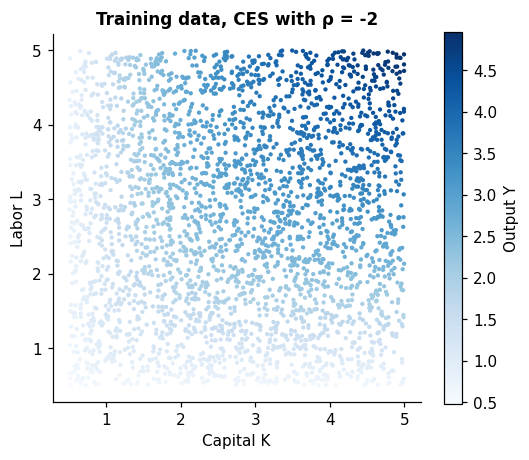

In [48]:
def make_ces_data(n, rho, noise=0.02, seed=0):
    g = torch.Generator().manual_seed(seed)
    # columns: K, L
    X = K_LO + (K_HI - K_LO) * torch.rand(n, 2, generator=g)
    y = ces(X[:, 0], X[:, 1], rho)
    # noise = 2% of output s.d.
    y = y + noise * y.std() * torch.randn(n, generator=g)
    # y: (n, 1)
    return X, y.unsqueeze(1)

RHO_MAIN = -2.0
X_all, y_all = make_ces_data(3000, RHO_MAIN)
print("X:", X_all.shape, X_all.dtype, "| y:", y_all.shape)

fig, ax = plt.subplots(figsize=(5.4, 4.4))
sc = ax.scatter(X_all[:, 0], X_all[:, 1], c=y_all[:, 0], cmap="Blues", s=8, edgecolors="none")
fig.colorbar(sc, label="Output Y")
ax.set(xlabel="Capital K", ylabel="Labor L", aspect="equal", title=f"Training data, CES with ρ = {RHO_MAIN:g}")
ax.grid(False)
plt.show()

# Part 3 — Why Go Deep?

The **universal approximation theorem** says a single hidden layer can approximate any continuous function... *if it is wide enough*. "Wide enough" can mean astronomically wide. Depth is about **efficiency**: composing layers lets a network build complex functions out of simple pieces using far fewer neurons.

## 3.1 Depth means composition

A deep network is a composition of simple functions:

$$
f(x) = W_L\,\phi\!\Big(W_{L-1}\,\phi\big(\cdots\phi(W_1 x + b_1)\cdots\big) + b_{L-1}\Big) + b_L
$$

A layer with $n_{in}$ inputs and $n_{out}$ outputs has $n_{in}\cdot n_{out}$ weights plus $n_{out}$ biases. Let's count parameters for a few architectures with 2 inputs ($K, L$) and 1 output ($Y$).

In [49]:
def count_params(sizes):
    return sum((n_in + 1) * n_out for n_in, n_out in zip(sizes[:-1], sizes[1:]))

for sizes in [[2, 16, 1], [2, 560, 1], [2, 32, 32, 32, 1], [2, 64, 64, 64, 1], [2, 256, 256, 256, 1]]:
    depth = len(sizes) - 2
    print(f"{str(sizes):<24} hidden layers: {depth}   parameters: {count_params(sizes):>7,}")

[2, 16, 1]               hidden layers: 1   parameters:      65
[2, 560, 1]              hidden layers: 1   parameters:   2,241
[2, 32, 32, 32, 1]       hidden layers: 3   parameters:   2,241
[2, 64, 64, 64, 1]       hidden layers: 3   parameters:   8,577
[2, 256, 256, 256, 1]    hidden layers: 3   parameters: 132,609


Note that `[2, 560, 1]` and `[2, 32, 32, 32, 1]` have exactly the same number of parameters (2,241). We'll race them against each other in Part 5.

## 3.2 What depth buys you: the sawtooth example

A ReLU network computes a **piecewise linear** function. The more linear pieces it can make, the more complex the shapes it can fit. Recall the approximation of the non-linear function in a linear piece-wise from last week

Take a "tent" built from just **2 ReLU neurons**: $t(x) = 2\,\text{ReLU}(x) - 4\,\text{ReLU}(x - 0.5)$ on $[0,1]$. Now *compose* it with itself:
- 1 layer (2 neurons) → 2 pieces
- 2 layers (4 neurons) → 4 pieces
- $k$ layers ($2k$ neurons) → $2^k$ pieces

The number of pieces **doubles with every layer**, but grows only **linearly** with neurons in a single wide layer (one neuron adds at most one kink). To match 6 layers (12 neurons, 64 pieces), a shallow net needs about 63 neurons.

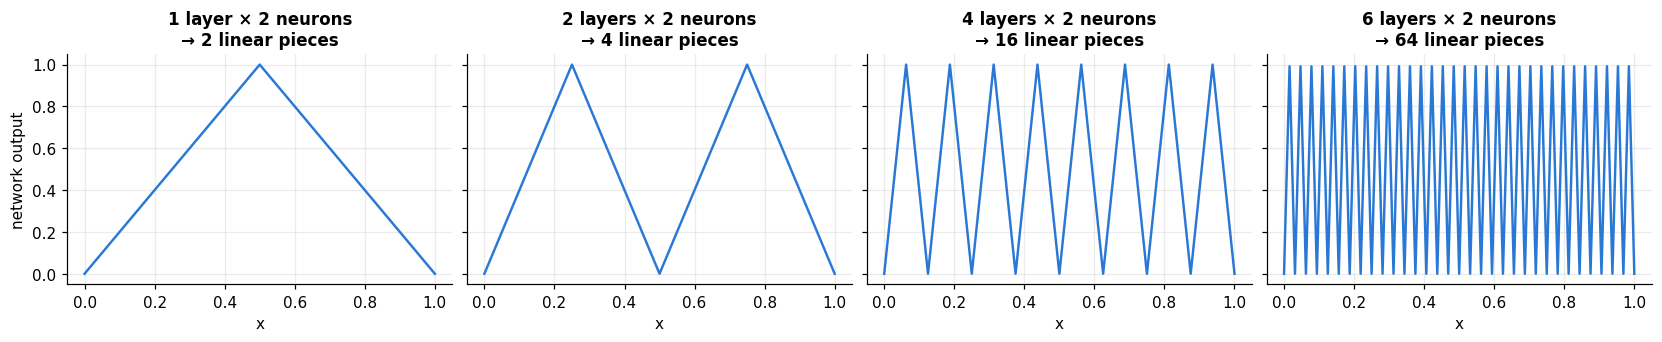

In [50]:
def tent(x):
    return 2 * torch.relu(x) - 4 * torch.relu(x - 0.5)

x = torch.linspace(0, 1, 4001)
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True, constrained_layout=True)
h = x
for k in range(1, 7):
    h = tent(h)
    if k in (1, 2, 4, 6):
        ax = axes[[1, 2, 4, 6].index(k)]
        ax.plot(x, h, color=COLORS[0], lw=1.6)
        ax.set_title(f"{k} layer{'s' if k > 1 else ''} × 2 neurons\n→ {2**k} linear pieces")
        ax.set_xlabel("x")
axes[0].set_ylabel("network output")
plt.show()

So for functions with **repeated, compositional structure**, depth can be *exponentially* more efficient than width. Two caveats: training does not always *find* such clever solutions, and many functions don't have this structure. Whether depth helps on a given problem is an empirical question, and we'll test it on CES in Part 5.

## 3.3 Activation functions and their derivatives

Without a nonlinear activation $\phi$, stacking layers is pointless: a composition of linear maps is just one linear map. Let's plot the common choices **and their derivatives**, computed with autograd. Remember we did this 2-3 weeks ago as well.

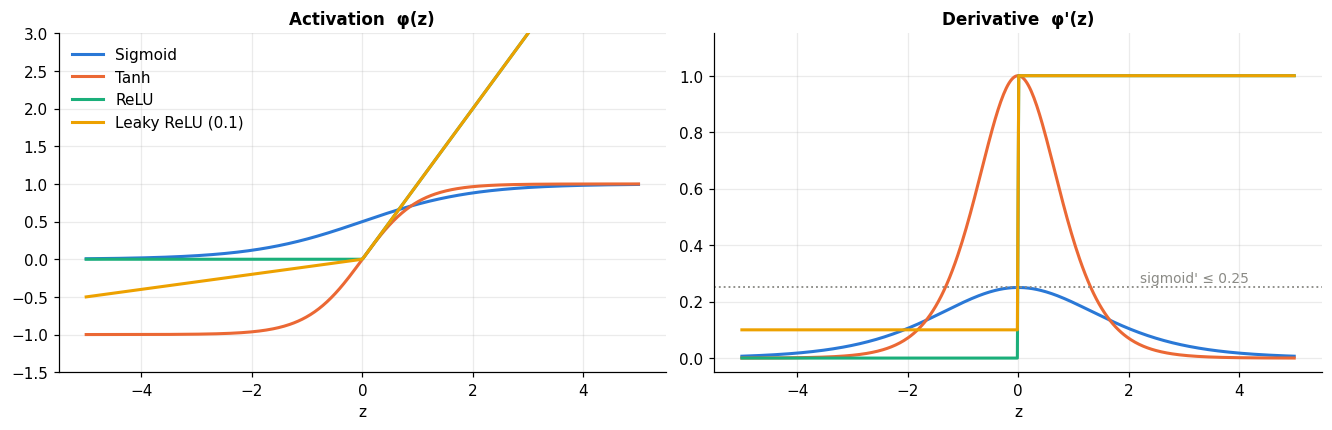

In [51]:
z = torch.linspace(-5, 5, 400, requires_grad=True)
activations = {
    "Sigmoid": torch.sigmoid,
    "Tanh": torch.tanh,
    "ReLU": torch.relu,
    "Leaky ReLU (0.1)": lambda t: nn.functional.leaky_relu(t, 0.1),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for (name, f), color in zip(activations.items(), COLORS):
    out = f(z)
    grad, = torch.autograd.grad(out.sum(), z)
    axes[0].plot(z.detach(), out.detach(), color=color, label=name)
    axes[1].plot(z.detach(), grad, color=color, label=name)
axes[0].set(title="Activation  φ(z)", xlabel="z", ylim=(-1.5, 3))
axes[1].set(title="Derivative  φ'(z)", xlabel="z", ylim=(-0.05, 1.15))
axes[1].axhline(0.25, color=GRAY, ls=":", lw=1.2)
axes[1].annotate("sigmoid' ≤ 0.25", xy=(2.2, 0.27), color=GRAY, fontsize=9)
axes[0].legend(loc="upper left")
plt.show()

**The key observation:** the sigmoid's derivative is never larger than **0.25**. Backpropagation multiplies one such factor per layer, so through 10 sigmoid layers the gradient can shrink by up to $0.25^{10}\approx 10^{-6}$. ReLU's derivative is exactly 1 for positive inputs, so it passes gradients through unchanged.

## 3.4 Vanishing gradients: an experiment

We build a **20-layer** network, push a batch of our CES data through it, backpropagate once, and measure the size of the gradient at each layer.

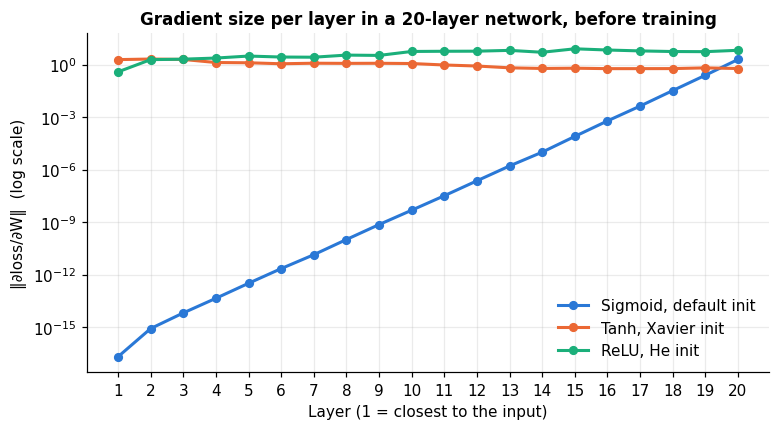

In [52]:
def make_deep_net(depth, width, act, init=None, in_dim=2):
    layers, prev = [], in_dim
    for _ in range(depth):
        lin = nn.Linear(prev, width)
        if init == "xavier":
            nn.init.xavier_normal_(lin.weight); nn.init.zeros_(lin.bias)
        elif init == "he":
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu"); nn.init.zeros_(lin.bias)
        layers += [lin, act()]
        prev = width
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)

def layer_grad_norms(net, X, y):
    net.zero_grad()
    nn.functional.mse_loss(net(X), y).backward()
    return [m.weight.grad.norm().item() for m in net if isinstance(m, nn.Linear)][:-1]

# standardized inputs: We have been through this multiple times
Xb = (X_all[:512] - X_all.mean(0)) / X_all.std(0)
yb = y_all[:512]

configs = [("Sigmoid, default init", nn.Sigmoid, None),
           ("Tanh, Xavier init", nn.Tanh, "xavier"),
           ("ReLU, He init", nn.ReLU, "he")]

fig, ax = plt.subplots(figsize=(8, 4))
for (label, act, init), color in zip(configs, COLORS):
    torch.manual_seed(0)
    norms = layer_grad_norms(make_deep_net(20, 64, act, init), Xb, yb)
    ax.semilogy(range(1, 21), norms, "o-", color=color, ms=5, label=label)
ax.set(xlabel="Layer (1 = closest to the input)", ylabel="‖∂loss/∂W‖  (log scale)",
       title="Gradient size per layer in a 20-layer network, before training", xticks=range(1, 21))
ax.legend()
plt.show()

With sigmoid, the gradient reaching the first layers is **orders of magnitude** smaller than at the top: the early layers barely learn. Tanh with Xavier init and ReLU with He init keep gradients at a similar size throughout the network.

### Why initialization matters

Each layer multiplies the signal by a random weight matrix. If the weights are slightly too small, the signal shrinks a little at every layer; slightly too large, it grows. Over 30 layers, "a little" compounds into vanishing or exploding.

For ReLU, **He initialization** draws $W_{ij}\sim\mathcal N(0,\,2/n_{in})$. The factor 2 compensates for ReLU zeroing out half its inputs. Let's track the spread of activations through 30 ReLU layers for three weight scales.

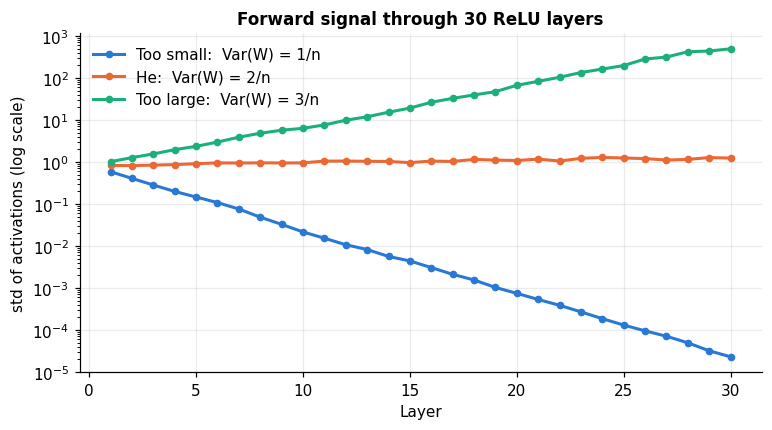

In [53]:
torch.manual_seed(0)
depth, width = 30, 256
x0 = torch.randn(1000, width)

fig, ax = plt.subplots(figsize=(8, 4))
for (label, gain), color in zip([("Too small:  Var(W) = 1/n", 1.0),
                                 ("He:  Var(W) = 2/n", 2.0),
                                 ("Too large:  Var(W) = 3/n", 3.0)], COLORS):
    h, stds = x0, []
    for _ in range(depth):
        W = torch.randn(width, width) * np.sqrt(gain / width)
        h = torch.relu(h @ W.T)
        stds.append(h.std().item())
    ax.semilogy(range(1, depth + 1), stds, "o-", ms=4, color=color, label=label)
ax.set(xlabel="Layer", ylabel="std of activations (log scale)",
       title="Forward signal through 30 ReLU layers")
ax.legend()
plt.show()

Only He initialization keeps the signal stable. The good news: PyTorch's `nn.Linear` already uses a sensible default initialization, so for moderately deep networks you rarely need to touch it. But when a deep network refuses to train, initialization and activation choice are the first suspects.

# Part 4 — A Feedforward Network the PyTorch Way

Last week we wrote the forward pass, backward pass and update by hand. PyTorch splits this into reusable building blocks:

| Building block | Role |
|---|---|
| `nn.Linear`, `nn.ReLU`, ... | layers |
| `nn.Module` / `nn.Sequential` | a model = layers + a `forward` method |
| `nn.MSELoss`, `nn.CrossEntropyLoss`, ... | loss functions |
| `torch.optim.SGD`, `torch.optim.Adam`, ... | update rules |
| `Dataset`, `DataLoader` | feeding data in mini-batches |

## 4.1 `nn.Linear`: one layer

`nn.Linear(n_in, n_out)` computes $xW^\top + b$. Its weight has shape `(n_out, n_in)`.

In [54]:
torch.manual_seed(0)
layer = nn.Linear(2, 3)
print("weight:", layer.weight.shape, "| bias:", layer.bias.shape)

# 2 samples, 2 features
x_demo = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
print("layer(x)      :\n", layer(x_demo))
print("x @ W.T + b   :\n", x_demo @ layer.weight.T + layer.bias)

weight: torch.Size([3, 2]) | bias: torch.Size([3])
layer(x)      :
 tensor([[ 0.7393, -1.0621,  0.0441],
        [ 1.4874, -3.2668, -0.1213]], grad_fn=<AddmmBackward0>)
x @ W.T + b   :
 tensor([[ 0.7393, -1.0621,  0.0441],
        [ 1.4874, -3.2668, -0.1213]], grad_fn=<AddBackward0>)


## 4.2 `nn.Sequential`: stacking layers

The quickest way to build a feedforward network: list the layers in order.

In [55]:
model_seq = nn.Sequential(
    nn.Linear(2, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
print(model_seq)
print("parameters:", sum(p.numel() for p in model_seq.parameters()),
      "| by our formula:", count_params([2, 32, 32, 1]))

Sequential(
  (0): Linear(in_features=2, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
parameters: 1185 | by our formula: 1185


## 4.3 A custom `nn.Module`

For anything beyond a plain stack, write a class that inherits from `nn.Module`:
- define the layers in `__init__`,
- describe the computation in `forward`.

Two extras that pay off:
1. **Configurable depth and width**, so we can run experiments with one line.
2. **Input standardization inside the model.** Networks train much better on inputs with mean 0 and s.d. 1. Storing the training mean and s.d. as **buffers** (saved with the model, but not trained) means the model takes *raw* $(K, L)$, so predictions and derivatives are always in economic units.

In [56]:
class Standardize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        # buffers move with .to(device) and are saved,
        self.register_buffer("mean", mean)
        # but are NOT updated by the optimizer
        self.register_buffer("std", std)

    def forward(self, x):
        return (x - self.mean) / self.std


class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim=1, activation=nn.ReLU, x_mean=None, x_std=None):
        super().__init__()
        self.scale = Standardize(x_mean, x_std) if x_mean is not None else nn.Identity()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), activation()]
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(self.scale(x))


demo = MLP(2, [64, 64, 64])
print(demo)
print("trainable parameters:", sum(p.numel() for p in demo.parameters() if p.requires_grad))

MLP(
  (scale): Identity()
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
trainable parameters: 8577


## 4.4 Datasets and DataLoaders

- `TensorDataset(X, y)` pairs inputs with targets.
- `random_split` divides it into train / validation / test.
- `DataLoader` serves **shuffled mini-batches**. Instead of computing the gradient on all 3,000 points (slow) or one point (noisy), we use batches of 64: **mini-batch stochastic gradient descent**.

Three splits, three jobs: **train** to fit the weights, **validation** to monitor and make choices, **test** touched once at the end for an honest score.

In [57]:
def make_loaders(X, y, batch_size=64, val_frac=0.15, test_frac=0.15, seed=0):
    ds = TensorDataset(X, y)
    n_val, n_test = int(val_frac * len(ds)), int(test_frac * len(ds))
    train_ds, val_ds, test_ds = random_split(
        ds, [len(ds) - n_val - n_test, n_val, n_test], generator=torch.Generator().manual_seed(seed))
    X_train = X[train_ds.indices]
    stats = (X_train.mean(0), X_train.std(0))           # computed on TRAINING data only
    return (DataLoader(train_ds, batch_size=batch_size, shuffle=True),
            DataLoader(val_ds, batch_size=1024),
            DataLoader(test_ds, batch_size=1024),
            stats)

train_loader, val_loader, test_loader, (x_mean, x_std) = make_loaders(X_all, y_all)
print(f"train: {len(train_loader.dataset)}  val: {len(val_loader.dataset)}  test: {len(test_loader.dataset)}")
print(f"batches per epoch: {len(train_loader)}")

xb, yb = next(iter(train_loader))
print("one batch ->", xb.shape, yb.shape)

train: 2100  val: 450  test: 450
batches per epoch: 33
one batch -> torch.Size([64, 2]) torch.Size([64, 1])


## 4.5 The training loop

Every PyTorch training loop is the same five steps, the same ones we did by hand last week:

```
optimizer.zero_grad()      # 1. reset gradients (they accumulate!)
pred = model(xb)           # 2. forward pass
loss = loss_fn(pred, yb)   # 3. compute the loss
loss.backward()            # 4. backward pass: fills p.grad for every parameter
optimizer.step()           # 5. update: p <- p - lr * p.grad  (for plain SGD)
```

First, one step in slow motion:

In [58]:
torch.manual_seed(0)
model = MLP(2, [64, 64, 64], x_mean=x_mean, x_std=x_std).to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

first_w = model.net[0].weight
xb, yb = xb.to(device), yb.to(device)

optimizer.zero_grad()
loss = loss_fn(model(xb), yb)
print(f"loss before step: {loss.item():.4f}")
loss.backward()
print(f"gradient of first layer, shape {tuple(first_w.grad.shape)}, norm {first_w.grad.norm():.4f}")
w_before = first_w.detach().clone()
optimizer.step()
print(f"weights moved by: {(first_w.detach() - w_before).norm():.4f}  (= lr × grad norm = {0.05 * first_w.grad.norm():.4f})")
with torch.no_grad():
    print(f"loss after step : {loss_fn(model(xb), yb).item():.4f}")

loss before step: 6.4880
gradient of first layer, shape (64, 2), norm 0.2529
weights moved by: 0.0126  (= lr × grad norm = 0.0126)
loss after step : 4.3692


### The shape pitfall from Part 2

If the target has shape `(n,)` and the prediction `(n, 1)`, broadcasting builds an `(n, n)` matrix of differences. The loss is computed, but it's the **wrong loss**. PyTorch only warns you.

In [59]:
import warnings
pred_demo = torch.tensor([[1.0], [2.0], [3.0]])
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    wrong = nn.functional.mse_loss(pred_demo, torch.tensor([1.0, 2.0, 3.0]))     # shape (3,)
    print("target (3,)  -> loss =", wrong.item(), "  <- should be 0!")
    print("warning:", str(w[0].message)[:90], "...")
right = nn.functional.mse_loss(pred_demo, torch.tensor([[1.0], [2.0], [3.0]]))    # shape (3, 1)
print("target (3,1) -> loss =", right.item())

target (3,)  -> loss = 1.3333333730697632   <- should be 0!
target (3,1) -> loss = 0.0


### Reusable training functions

We wrap the loop into functions we'll use for the rest of the course.
- `model.train()` / `model.eval()` switch layers like dropout and batch norm (next week) between their training and evaluation behavior. Good habit to start now.
- We use the **Adam** optimizer: like SGD, but with an adaptive step size for each parameter. It's the usual default; we'll study optimizers properly later.

In [60]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        total += loss_fn(model(xb), yb).item() * len(xb)
    return total / len(loader.dataset)


def fit(model, train_loader, val_loader, epochs=100, lr=1e-3, print_every=None):
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train": [], "val": []}
    best_val, best_state, best_epoch = float("inf"), None, 0
    for epoch in range(1, epochs + 1):
        history["train"].append(train_one_epoch(model, train_loader, loss_fn, optimizer))
        history["val"].append(evaluate(model, val_loader, loss_fn))
        if history["val"][-1] < best_val:                       # remember the best model so far
            best_val, best_epoch = history["val"][-1], epoch
            best_state = copy.deepcopy(model.state_dict())
        if print_every and (epoch % print_every == 0 or epoch == 1):
            print(f"epoch {epoch:4d} | train MSE {history['train'][-1]:.5f} | val MSE {history['val'][-1]:.5f}")
    history["best_epoch"], history["best_state"] = best_epoch, best_state
    return history

## 4.6 Train on the CES data

In [61]:
torch.manual_seed(0)
model = MLP(2, [64, 64, 64], x_mean=x_mean, x_std=x_std).to(device)
history = fit(model, train_loader, val_loader, epochs=150, lr=3e-3, print_every=25)

epoch    1 | train MSE 1.52652 | val MSE 0.34261
epoch   25 | train MSE 0.00073 | val MSE 0.00073
epoch   50 | train MSE 0.00060 | val MSE 0.00063
epoch   75 | train MSE 0.00072 | val MSE 0.00086
epoch  100 | train MSE 0.00070 | val MSE 0.00076
epoch  125 | train MSE 0.00061 | val MSE 0.00073
epoch  150 | train MSE 0.00097 | val MSE 0.00088


Test MSE: 0.00082   |   Test R²: 0.99932


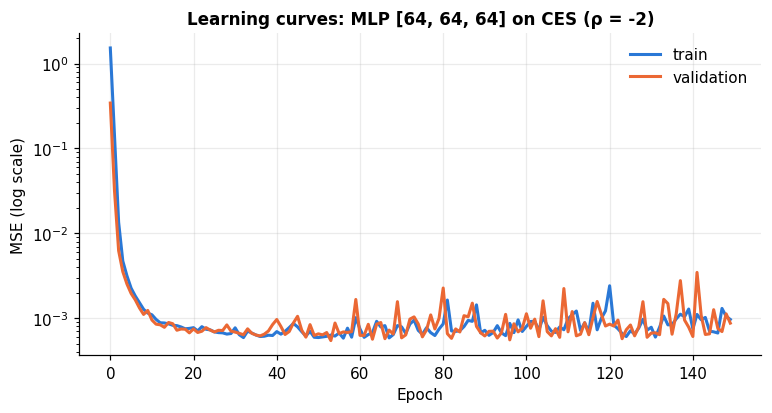

In [62]:
def r2_score_loader(model, loader):
    X, y = loader.dataset[:]
    with torch.no_grad():
        pred = model(X.to(device)).cpu()
    return 1 - ((pred - y)**2).sum().item() / ((y - y.mean())**2).sum().item()

test_mse = evaluate(model, test_loader, nn.MSELoss())
print(f"Test MSE: {test_mse:.5f}   |   Test R²: {r2_score_loader(model, test_loader):.5f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogy(history["train"], color=COLORS[0], label="train")
ax.semilogy(history["val"], color=COLORS[1], label="validation")
ax.set(xlabel="Epoch", ylabel="MSE (log scale)", title="Learning curves: MLP [64, 64, 64] on CES (ρ = -2)")
ax.legend()
plt.show()

## 4.7 What did the network learn?

Because we know the true function, we can compare **everywhere** on the $(K, L)$ square, not just at the data points.

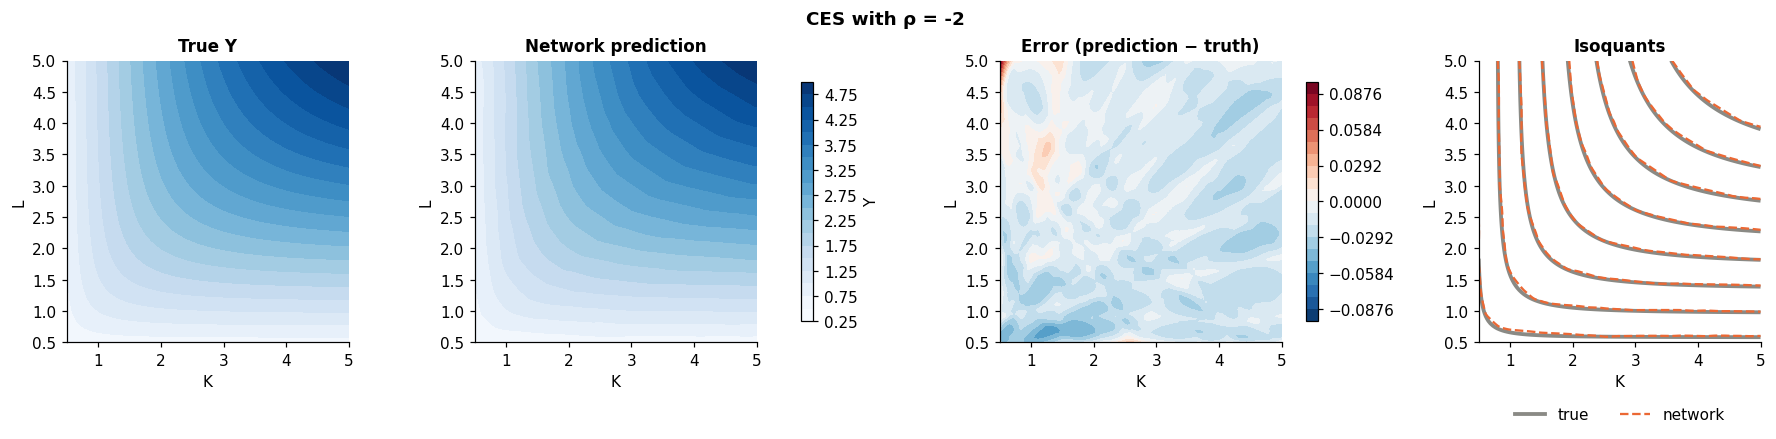

In [63]:
def grid_predict(model, n=120):
    kg, lg = torch.meshgrid(torch.linspace(K_LO, K_HI, n), torch.linspace(K_LO, K_HI, n), indexing="xy")
    Xg = torch.stack([kg.ravel(), lg.ravel()], dim=1)
    model.eval()
    with torch.no_grad():
        pred = model(Xg.to(device)).cpu().reshape(n, n)
    return kg.numpy(), lg.numpy(), pred.numpy()

def plot_fit(model, rho, title_prefix=""):
    kg, lg, pred = grid_predict(model)
    true = ces(kg, lg, rho)
    err = pred - true
    vmin, vmax = true.min(), true.max()
    elim = np.abs(err).max()

    fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), constrained_layout=True)
    for ax, data, title in [(axes[0], true, "True Y"), (axes[1], pred, "Network prediction")]:
        im = ax.contourf(kg, lg, data, levels=20, cmap="Blues", vmin=vmin, vmax=vmax)
        ax.set(title=title, xlabel="K", ylabel="L", aspect="equal")
    fig.colorbar(im, ax=axes[:2], shrink=0.85, label="Y")
    im = axes[2].contourf(kg, lg, err, levels=np.linspace(-elim, elim, 21), cmap="RdBu_r")
    axes[2].set(title="Error (prediction − truth)", xlabel="K", ylabel="L", aspect="equal")
    fig.colorbar(im, ax=axes[2], shrink=0.85)
    levels = np.linspace(0.75, 4.25, 8)
    axes[3].contour(kg, lg, true, levels=levels, colors=GRAY, linewidths=2.5)
    axes[3].contour(kg, lg, pred, levels=levels, colors=COLORS[1], linewidths=1.5, linestyles="--")
    axes[3].plot([], [], color=GRAY, lw=2.5, label="true")
    axes[3].plot([], [], color=COLORS[1], lw=1.5, ls="--", label="network")
    axes[3].set(title="Isoquants", xlabel="K", ylabel="L", aspect="equal")
    axes[3].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
    for ax in axes:
        ax.grid(False)
    fig.suptitle(f"{title_prefix}CES with ρ = {rho:g}", fontweight="bold")
    plt.show()

plot_fit(model, RHO_MAIN)

The isoquants are almost indistinguishable. The error map shows *where* the network struggles: typically at the **edges and corners** of the input space, where there is less data around each point.

### Economic content: the learned marginal products

A trained network is a differentiable function of its inputs. With autograd we can compute the network's **implied marginal product of capital** $\partial\hat Y/\partial K$ and compare it with the true CES formula:

$$
MPK = A\,\alpha\,K^{\rho-1}\left[\alpha K^\rho + (1-\alpha)L^\rho\right]^{\frac{1}{\rho}-1}
$$

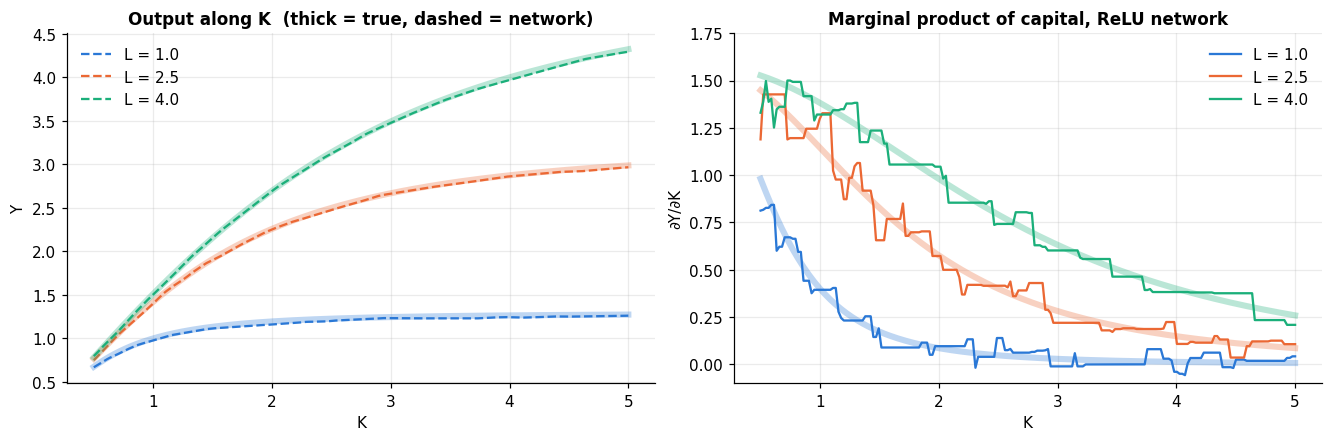

In [64]:
def ces_mpk(K, L, rho, alpha=ALPHA, A=A_TFP):
    return A * alpha * K**(rho - 1) * (alpha * K**rho + (1 - alpha) * L**rho) ** (1 / rho - 1)

def network_mpk(model, K, L):
    X = torch.stack([K, L], dim=1).to(device).requires_grad_(True)
    model.eval()
    grads, = torch.autograd.grad(model(X).sum(), X)
    return grads[:, 0].cpu()                    # column 0 = derivative w.r.t. K

K_line = torch.linspace(K_LO, K_HI, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), constrained_layout=True)
for L_val, color in zip([1.0, 2.5, 4.0], COLORS):
    L_line = torch.full_like(K_line, L_val)
    with torch.no_grad():
        y_hat = model(torch.stack([K_line, L_line], 1).to(device)).cpu()[:, 0]
    axes[0].plot(K_line, ces(K_line, L_line, RHO_MAIN), color=color, lw=4, alpha=0.3)
    axes[0].plot(K_line, y_hat, color=color, lw=1.5, ls="--", label=f"L = {L_val}")
    axes[1].plot(K_line, ces_mpk(K_line, L_line, RHO_MAIN), color=color, lw=4, alpha=0.3)
    axes[1].plot(K_line, network_mpk(model, K_line, L_line), color=color, lw=1.5, label=f"L = {L_val}")
axes[0].set(title="Output along K  (thick = true, dashed = network)", xlabel="K", ylabel="Y")
axes[1].set(title="Marginal product of capital, ReLU network", xlabel="K", ylabel="∂Y/∂K", ylim=(-0.1, 1.75))
axes[0].legend(); axes[1].legend()
plt.show()

The output levels are spot on and the MPK follows the right shape, but it looks like a **staircase**. That's no bug: a ReLU network is *piecewise linear*, so its derivative is *piecewise constant*. The network was only trained on levels, and nothing forces the derivative to be smooth.

When the economics lives in the derivatives (marginal products, elasticities, and later Euler equations in dynamic models), use a **smooth activation**. Let's swap ReLU for **SiLU** ($z\cdot\text{sigmoid}(z)$, a smooth cousin of ReLU) and change nothing else.

Test MSE  ReLU: 0.00082   SiLU: 0.00079


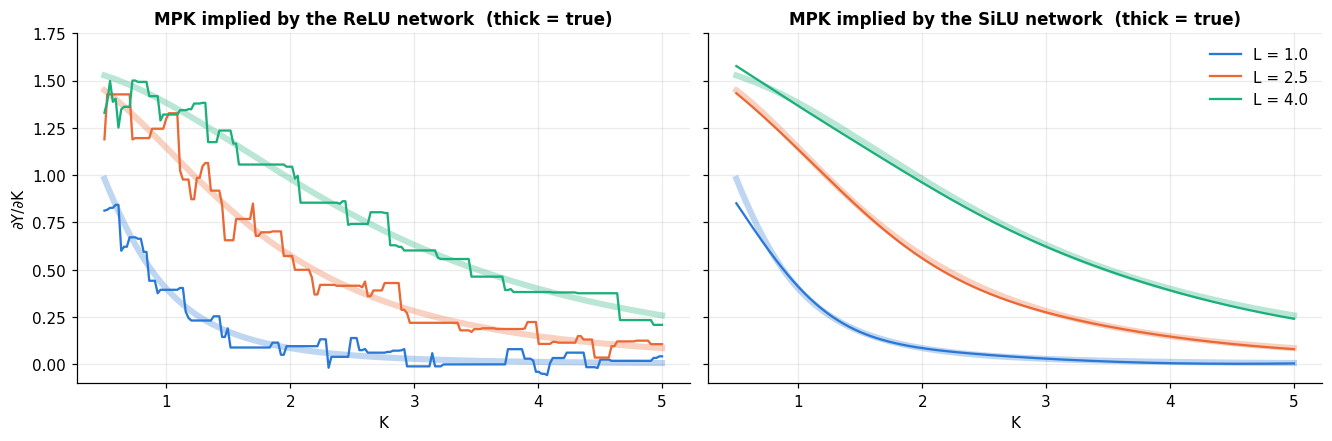

In [65]:
torch.manual_seed(0)
model_silu = MLP(2, [64, 64, 64], activation=nn.SiLU, x_mean=x_mean, x_std=x_std).to(device)
hist_silu = fit(model_silu, train_loader, val_loader, epochs=150, lr=3e-3)
print(f"Test MSE  ReLU: {evaluate(model, test_loader, nn.MSELoss()):.5f}   SiLU: {evaluate(model_silu, test_loader, nn.MSELoss()):.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True, constrained_layout=True)
for ax, net, name in [(axes[0], model, "ReLU"), (axes[1], model_silu, "SiLU")]:
    for L_val, color in zip([1.0, 2.5, 4.0], COLORS):
        L_line = torch.full_like(K_line, L_val)
        ax.plot(K_line, ces_mpk(K_line, L_line, RHO_MAIN), color=color, lw=4, alpha=0.3)
        ax.plot(K_line, network_mpk(net, K_line, L_line), color=color, lw=1.5, label=f"L = {L_val}")
    ax.set(title=f"MPK implied by the {name} network  (thick = true)", xlabel="K", ylim=(-0.1, 1.75))
axes[0].set_ylabel("∂Y/∂K")
axes[1].legend()
plt.show()

Similar fit in levels, but the SiLU network's marginal products are **smooth** and much closer to the truth. Lesson: the choice of activation is also a choice about what the network's *derivatives* look like.

---
# Part 5 — Experiment: Does Depth Always Win?

Now the race promised in Part 3. Two networks with **exactly the same number of parameters**:

- **Shallow:** one hidden layer with 560 neurons → 2,241 parameters
- **Deep:** three hidden layers with 32 neurons each → 2,241 parameters

Same data, same optimizer, same number of epochs. We train both on CES functions of increasing curvature. This time the data are **noise-free**, so any error is pure *approximation* error. To compare across $\rho$, we report the test **RMSE relative to the s.d. of $Y$**.

One more thing: neural network training is random (initialization, mini-batch order). So we repeat every run with **3 different seeds**. *Prediction before you run it: which network wins at ρ = −10?*

In [66]:
ARCHS = {"Shallow [560]": [560], "Deep [32, 32, 32]": [32, 32, 32]}
SEEDS = [0, 1, 2]
for name, hidden in ARCHS.items():
    print(f"{name:<20} parameters: {count_params([2, *hidden, 1]):,}")

results, trained = {}, {}
for rho in RHOS:
    X_r, y_r = make_ces_data(3000, rho, noise=0.0, seed=1)
    tr, va, te, (m, s) = make_loaders(X_r, y_r, seed=1)
    for name, hidden in ARCHS.items():
        for seed in SEEDS:
            torch.manual_seed(seed)
            net = MLP(2, hidden, x_mean=m, x_std=s).to(device)
            fit(net, tr, va, epochs=150, lr=3e-3)
            results[(rho, name, seed)] = np.sqrt(evaluate(net, te, nn.MSELoss())) / y_r.std().item()
            trained[(rho, name, seed)] = net
        errs = [results[(rho, name, sd)] for sd in SEEDS]
        print(f"ρ = {rho:>5g} | {name:<20} | relative RMSE by seed: " + "  ".join(f"{e:.4f}" for e in errs))

Shallow [560]        parameters: 2,241
Deep [32, 32, 32]    parameters: 2,241
ρ =   0.9 | Shallow [560]        | relative RMSE by seed: 0.0044  0.0076  0.0114
ρ =   0.9 | Deep [32, 32, 32]    | relative RMSE by seed: 0.0055  0.0059  0.0044
ρ =     0 | Shallow [560]        | relative RMSE by seed: 0.0119  0.0105  0.0030
ρ =     0 | Deep [32, 32, 32]    | relative RMSE by seed: 0.0133  0.0093  0.0091
ρ =    -2 | Shallow [560]        | relative RMSE by seed: 0.0112  0.0029  0.0076
ρ =    -2 | Deep [32, 32, 32]    | relative RMSE by seed: 0.0101  0.0122  0.0107
ρ =   -10 | Shallow [560]        | relative RMSE by seed: 0.0071  0.0128  0.0019
ρ =   -10 | Deep [32, 32, 32]    | relative RMSE by seed: 0.0093  0.0037  0.0084


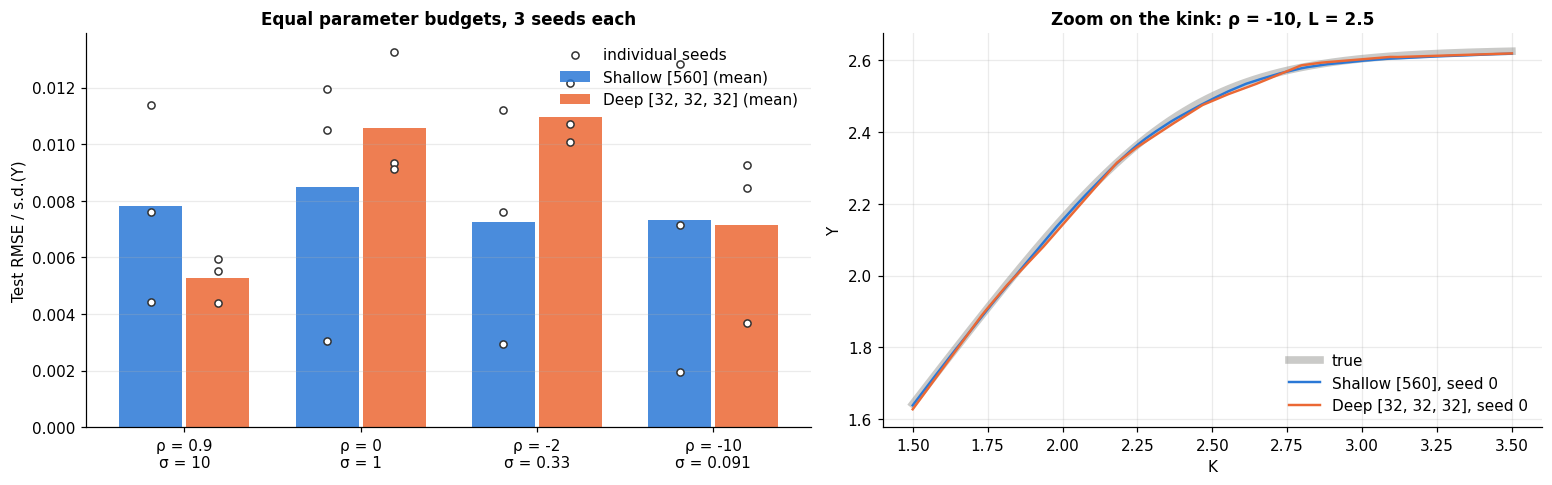

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), constrained_layout=True, gridspec_kw={"width_ratios": [1.1, 1]})

ax = axes[0]
xpos = np.arange(len(RHOS))
width = 0.38
for i, (name, color) in enumerate(zip(ARCHS, COLORS)):
    errs = np.array([[results[(rho, name, sd)] for sd in SEEDS] for rho in RHOS])
    xs = xpos + (i - 0.5) * width
    ax.bar(xs, errs.mean(1), width * 0.94, color=color, alpha=0.85, label=f"{name} (mean)")
    for j in range(len(SEEDS)):
        ax.scatter(xs, errs[:, j], s=22, color="white", edgecolors="#333333", linewidths=1, zorder=3,
                   label="individual seeds" if (i == 1 and j == 0) else None)
ax.set_xticks(xpos, [f"ρ = {r:g}\nσ = {1 / (1 - r):.2g}" for r in RHOS])
ax.set(ylabel="Test RMSE / s.d.(Y)", title="Equal parameter budgets, 3 seeds each")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)

# Zoom in on the kink of the most Leontief-like technology
ax = axes[1]
rho_k, L_val = -10.0, 2.5
K_line_z = torch.linspace(1.5, 3.5, 400)
L_line_z = torch.full_like(K_line_z, L_val)
ax.plot(K_line_z, ces(K_line_z, L_line_z, rho_k), color=GRAY, lw=5, alpha=0.45, label="true")
for name, color in zip(ARCHS, COLORS):
    with torch.no_grad():
        y_hat = trained[(rho_k, name, 0)](torch.stack([K_line_z, L_line_z], 1).to(device)).cpu()[:, 0]
    ax.plot(K_line_z, y_hat, color=color, lw=1.6, label=f"{name}, seed 0")
ax.set(title=f"Zoom on the kink: ρ = {rho_k:g}, L = {L_val}", xlabel="K", ylabel="Y")
ax.legend(loc="lower right")
plt.show()

**Surprise: no clear winner.** Both networks fit every technology, including the near-Leontief one, and the differences between architectures are about as large as the differences between **seeds** of the same architecture.

Why doesn't depth help here, after the sawtooth example? Because the Leontief kink is **easy for a single layer**. One ReLU neuron is enough:

$$
\min(K, L) = L - \text{ReLU}(L - K)
$$

In [68]:
K_t, L_t = 5 * torch.rand(5), 5 * torch.rand(5)
print("min(K, L)        :", torch.minimum(K_t, L_t).numpy().round(3))
print("L - ReLU(L - K)  :", (L_t - torch.relu(L_t - K_t)).numpy().round(3))

min(K, L)        : [3.857 1.893 0.289 2.662 4.22 ]
L - ReLU(L - K)  : [3.857 1.893 0.289 2.662 4.22 ]


CES is a smooth function of just **two inputs** with **one** kink along a ray. That's exactly the kind of structure a wide single layer handles well. Depth pays off when the function is built by **composing** simpler pieces, often over many inputs: the sawtooth, images (edges → shapes → objects), or value functions over many state variables, which we'll meet in the RL part of the course.

**Two lessons that matter more than the winner:**
1. **Theory tells you what's possible, experiments tell you what happens.** "Deeper is better" is a tendency, not a law.
2. **Never trust a single run.** With one seed you could have "found" a clear winner in either direction. Report results across several seeds, just as you'd report standard errors.

---
# Part 6 — A First Look at Overfitting

So far we had 3,000 observations and a modest network. What happens with **little data** and a **big network**?

We take only **30 noisy observations** of the CES function and fit a network with 3 hidden layers of 256 neurons (≈ 133,000 parameters, over 4,000 per observation). We train for a long time and watch the validation loss on 1,000 fresh points.

In [69]:
X_small, y_small = make_ces_data(30, RHO_MAIN, noise=0.15, seed=7)
X_val_big, y_val_big = make_ces_data(1000, RHO_MAIN, noise=0.15, seed=8)

small_train = DataLoader(TensorDataset(X_small, y_small), batch_size=30, shuffle=True)   # full batch
small_val = DataLoader(TensorDataset(X_val_big, y_val_big), batch_size=1000)

torch.manual_seed(0)
big_net = MLP(2, [256, 256, 256], x_mean=X_small.mean(0), x_std=X_small.std(0)).to(device)
print(f"parameters: {sum(p.numel() for p in big_net.parameters()):,} for {len(X_small)} observations")
hist_of = fit(big_net, small_train, small_val, epochs=3000, lr=1e-3, print_every=500)

best_net = copy.deepcopy(big_net)
best_net.load_state_dict(hist_of["best_state"])

parameters: 132,609 for 30 observations
epoch    1 | train MSE 7.58270 | val MSE 6.21586
epoch  500 | train MSE 0.00240 | val MSE 0.04629
epoch 1000 | train MSE 0.00093 | val MSE 0.04711
epoch 1500 | train MSE 0.00030 | val MSE 0.05061
epoch 2000 | train MSE 0.00004 | val MSE 0.05529
epoch 2500 | train MSE 0.00032 | val MSE 0.05767
epoch 3000 | train MSE 0.00000 | val MSE 0.05583


<All keys matched successfully>

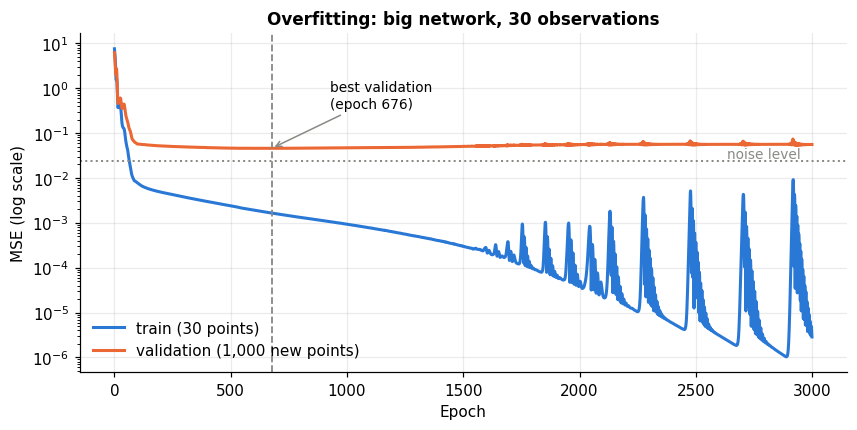

In [70]:
noise_var = (0.15 * y_small.std().item()) ** 2      # approximate irreducible error
be = hist_of["best_epoch"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(hist_of["train"], color=COLORS[0], label="train (30 points)")
ax.semilogy(hist_of["val"], color=COLORS[1], label="validation (1,000 new points)")
ax.axhline(noise_var, color=GRAY, ls=":", lw=1.3)
ax.annotate("noise level", xy=(2950, noise_var * 1.12), ha="right", color=GRAY, fontsize=9)
ax.axvline(be, color=GRAY, ls="--", lw=1.2)
ax.annotate(f"best validation\n(epoch {be})", xy=(be, hist_of["val"][be - 1]),
            xytext=(be + 250, hist_of["val"][be - 1] * 8), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=GRAY))
ax.set(xlabel="Epoch", ylabel="MSE (log scale)", title="Overfitting: big network, 30 observations")
ax.legend(loc="lower left")
plt.show()

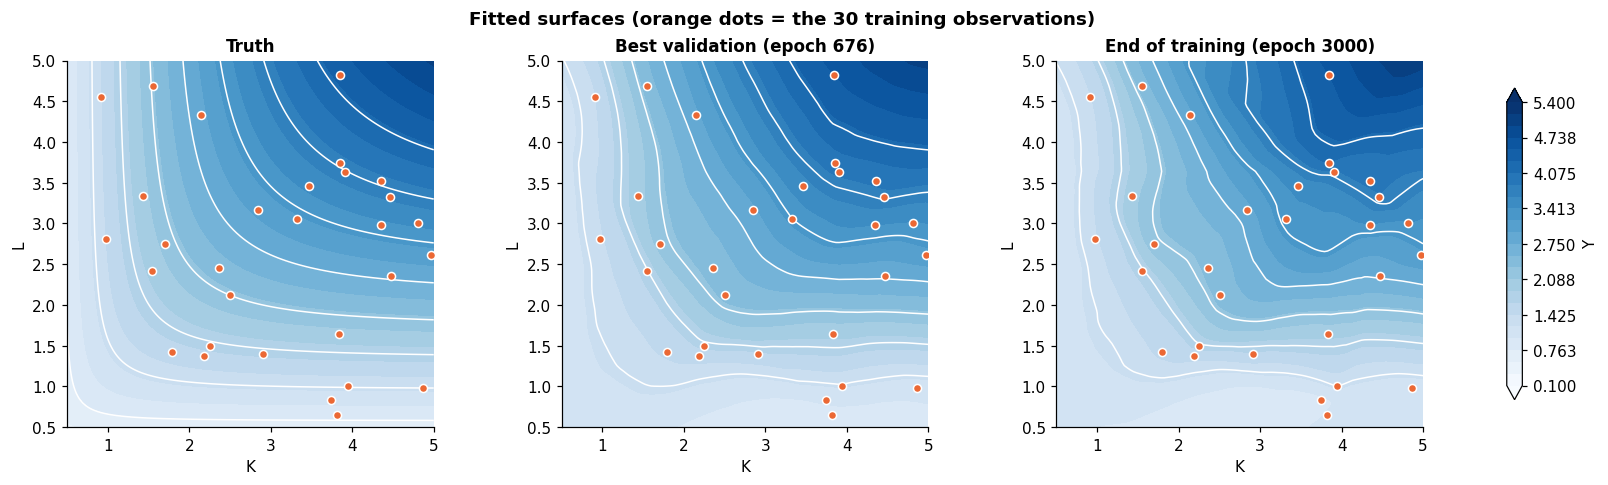

In [71]:
kg, lg, _ = grid_predict(best_net)
true = ces(kg, lg, RHO_MAIN)
panels = [("Truth", true), (f"Best validation (epoch {be})", grid_predict(best_net)[2]),
          ("End of training (epoch 3000)", grid_predict(big_net)[2])]
vmin, vmax = true.min(), true.max()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
for ax, (title, data) in zip(axes, panels):
    im = ax.contourf(kg, lg, data, levels=np.linspace(vmin - 0.4, vmax + 0.4, 25), cmap="Blues", extend="both")
    ax.contour(kg, lg, data, levels=np.linspace(0.75, 4.25, 8), colors="white", linewidths=1)
    ax.scatter(X_small[:, 0], X_small[:, 1], s=28, color=COLORS[1], edgecolors="white", linewidths=1, zorder=3)
    ax.set(title=title, xlabel="K", ylabel="L", aspect="equal")
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.85, label="Y")
fig.suptitle("Fitted surfaces (orange dots = the 30 training observations)", fontweight="bold")
plt.show()

**Reading the plots**

- The **training loss keeps falling** far below the noise level: the network is memorizing the noise in the 30 observations.
- The **validation loss** falls at first, bottoms out, then **creeps back up**. Past that point, extra epochs make the model *worse* on new data.
- The spikes in the training loss late in training are Adam overshooting once the loss is tiny. They're harmless here, but a sign that the learning rate is too large for this stage (learning-rate schedules come later).
- The fitted surface at the end has bumps and dents around the training points that have nothing to do with production technology. Its isoquants are no longer smooth or convex.

Saving the model at the best validation epoch, as our `fit` function does, is called **early stopping**. It is the first of several **regularization** tools.

**Next week:** regularization in depth (weight decay, dropout, early stopping, batch normalization) and better optimizers.

---
# Part 7 — Exercise: California Housing Prices

Time for real data. The **California housing** dataset (1990 census) has 20,640 districts with 8 features, and the target is the median house value in units of \$100,000.

| Feature | Meaning |
|---|---|
| `MedInc` | median income in the district (\$10,000s) |
| `HouseAge` | median house age |
| `AveRooms`, `AveBedrms` | average rooms / bedrooms per household |
| `Population`, `AveOccup` | population, average household size |
| `Latitude`, `Longitude` | location |

**Your tasks**

1. Load the data with `sklearn.datasets.fetch_california_housing()` and convert `X` and `y` to `float32` tensors (`y` with shape `(n, 1)`!).
2. Split into train / validation / test (70 / 15 / 15). You can reuse `make_loaders`.
3. **Baseline:** fit a linear regression (`sklearn.linear_model.LinearRegression`) on the training set and compute its test MSE and $R^2$.
4. Build an `MLP` with 8 inputs and hidden layers `[64, 64, 64]`. Use the training mean / s.d. for standardization.
5. Train it with `fit` (e.g. 100 epochs, `lr=1e-3`) and plot the learning curves.
6. Report the network's test MSE and $R^2$. How much does it beat the linear model?
7. Plot predicted vs. actual values for both models. What happens at the top of the price range? (Hint: look up how the target was recorded.)

**Bonus**

- **Marginal effects.** Using autograd, compute $\partial\hat y/\partial x_j$ for each observation in the test set. Which feature has the largest average effect (scale by the feature's s.d. to compare)? Does the effect of income look constant across districts, as a linear model would assume?
- **Architecture.** Try `[32]`, `[256]`, `[64, 64]` and `[128, 128, 128, 128]`. Does depth help here?
- **Where depth helps.** Repeat the Part 5 experiment with the sawtooth from Part 3 (4 layers deep) as the target function, using 1-D input. Does the deep network win now? Does training actually find the sawtooth?

The data downloads automatically the first time (an internet connection is needed once).

In [ ]:
# 1. Load the data
# YOUR CODE HERE

In [ ]:
# 2. Train / validation / test split
# YOUR CODE HERE

In [ ]:
# 3. Linear regression baseline
# YOUR CODE HERE

In [ ]:
# 4-5. Build and train the MLP, plot learning curves
# YOUR CODE HERE

In [ ]:
# 6-7. Evaluate and plot predicted vs. actual
# YOUR CODE HERE

---
## Solution

*Try the exercise yourself before looking!*

In [72]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression

housing = fetch_california_housing()
X_h = torch.tensor(housing.data, dtype=torch.float32)
y_h = torch.tensor(housing.target, dtype=torch.float32).unsqueeze(1)
feature_names = housing.feature_names
print("X:", X_h.shape, "| y:", y_h.shape)

tr_h, va_h, te_h, (m_h, s_h) = make_loaders(X_h, y_h, batch_size=128, seed=0)
X_tr, y_tr = tr_h.dataset[:]
X_te, y_te = te_h.dataset[:]

# Baseline: OLS
ols = LinearRegression().fit(X_tr.numpy(), y_tr.numpy())
pred_ols = torch.tensor(ols.predict(X_te.numpy()), dtype=torch.float32)

def mse_r2(pred, y):
    mse = ((pred - y)**2).mean().item()
    return mse, 1 - mse / y.var(unbiased=False).item()

# Neural network
torch.manual_seed(0)
net_h = MLP(8, [64, 64, 64], x_mean=m_h, x_std=s_h).to(device)
hist_h = fit(net_h, tr_h, va_h, epochs=100, lr=1e-3, print_every=20)
net_h.load_state_dict(hist_h["best_state"])                 # early stopping
with torch.no_grad():
    pred_nn = net_h(X_te.to(device)).cpu()

for name, pred in [("Linear regression", pred_ols), ("MLP [64, 64, 64]", pred_nn)]:
    mse, r2 = mse_r2(pred, y_te)
    print(f"{name:<18}  test MSE = {mse:.4f}   test R² = {r2:.4f}")

X: torch.Size([20640, 8]) | y: torch.Size([20640, 1])
epoch    1 | train MSE 2.02683 | val MSE 0.96873
epoch   20 | train MSE 0.29418 | val MSE 0.32081
epoch   40 | train MSE 0.26417 | val MSE 0.30071
epoch   60 | train MSE 0.24790 | val MSE 0.27756
epoch   80 | train MSE 0.23068 | val MSE 0.27796
epoch  100 | train MSE 0.22232 | val MSE 0.27127
Linear regression   test MSE = 1.1472   test R² = 0.1248
MLP [64, 64, 64]    test MSE = 0.2632   test R² = 0.7992


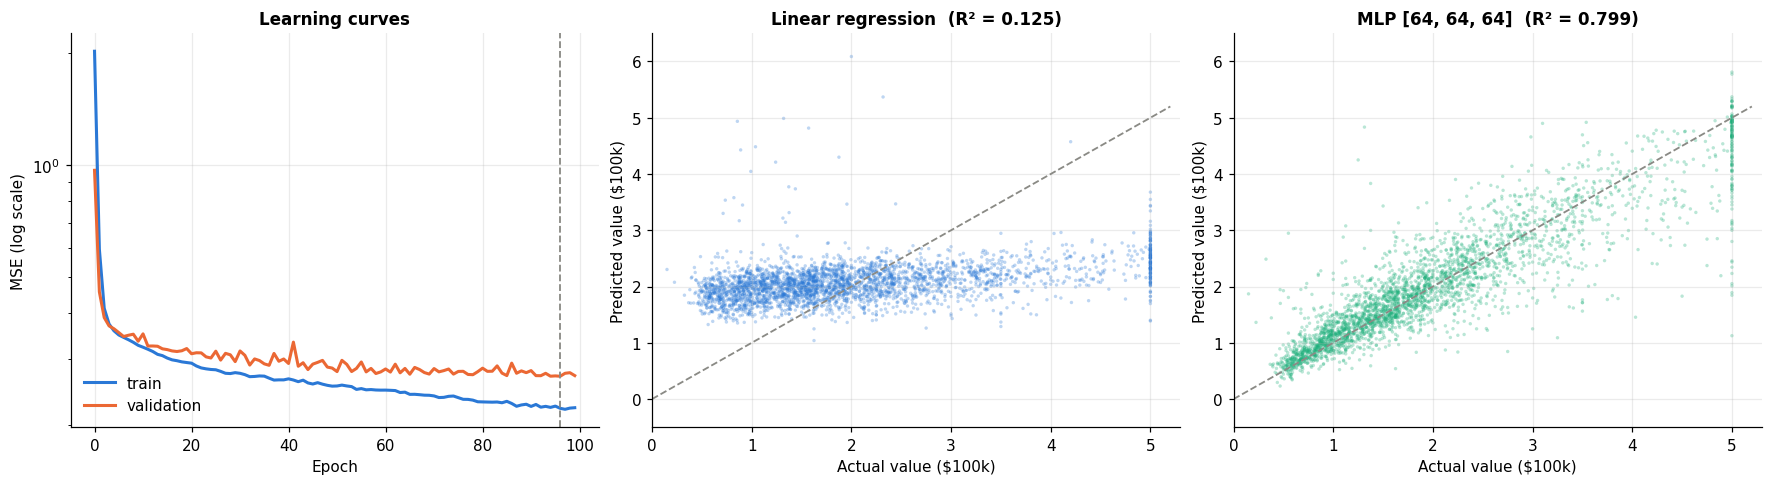

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), constrained_layout=True)

axes[0].semilogy(hist_h["train"], color=COLORS[0], label="train")
axes[0].semilogy(hist_h["val"], color=COLORS[1], label="validation")
axes[0].axvline(hist_h["best_epoch"] - 1, color=GRAY, ls="--", lw=1.2)
axes[0].set(title="Learning curves", xlabel="Epoch", ylabel="MSE (log scale)")
axes[0].legend()

for ax, pred, name, color in [(axes[1], pred_ols, "Linear regression", COLORS[0]),
                              (axes[2], pred_nn, "MLP [64, 64, 64]", COLORS[2])]:
    ax.scatter(y_te, pred, s=5, alpha=0.3, color=color, edgecolors="none")
    ax.plot([0, 5.2], [0, 5.2], color=GRAY, ls="--", lw=1.2)
    _, r2 = mse_r2(pred, y_te)
    ax.set(title=f"{name}  (R² = {r2:.3f})", xlabel="Actual value ($100k)", ylabel="Predicted value ($100k)",
           xlim=(0, 5.3), ylim=(-0.5, 6.5))
plt.show()

The vertical wall of points at 5.0 is a **censoring** artifact: house values above \$500,000 were recorded as \$500,001. Neither model can know the true value there. (Economists would reach for a Tobit-type model; a neural network has no built-in fix.)

### Bonus: marginal effects via autograd

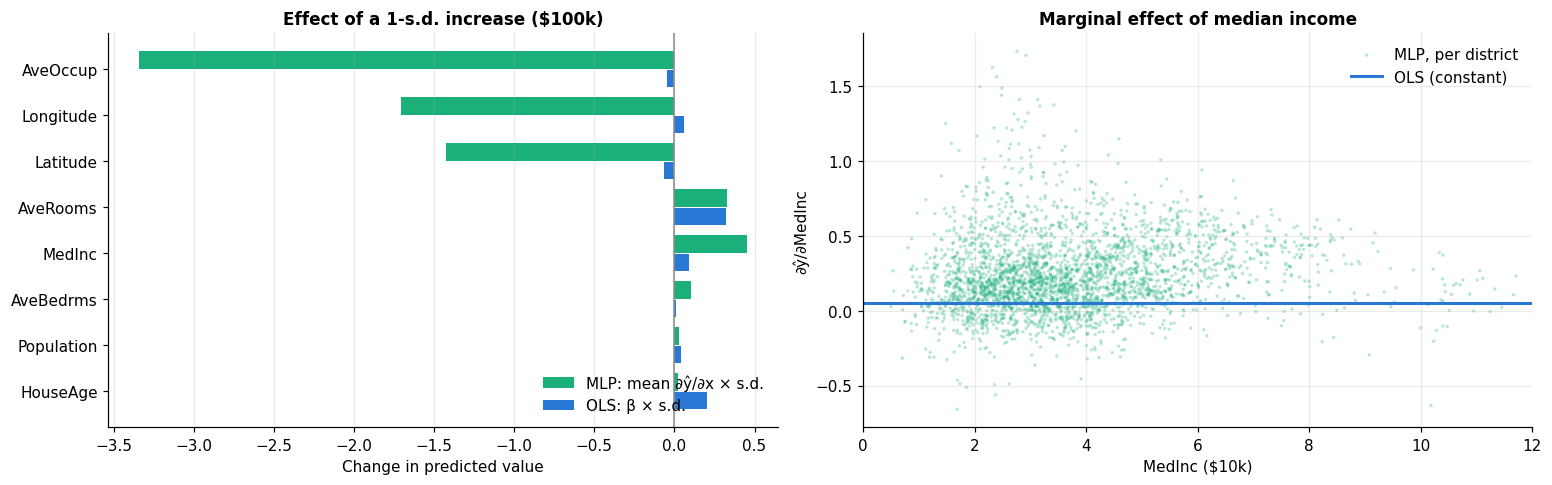

In [74]:
X_te_g = X_te.clone().to(device).requires_grad_(True)
net_h.eval()
grads, = torch.autograd.grad(net_h(X_te_g).sum(), X_te_g)
grads = grads.cpu()

# effect of a one-s.d. increase in each feature, averaged over test districts
scaled = grads * s_h
order = scaled.abs().mean(0).argsort()
ols_scaled = torch.tensor(ols.coef_[0]) * s_h

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), constrained_layout=True)
ax = axes[0]
ypos = np.arange(8)
ax.barh(ypos + 0.2, scaled.mean(0)[order], 0.38, color=COLORS[2], label="MLP: mean ∂ŷ/∂x × s.d.")
ax.barh(ypos - 0.2, ols_scaled[order], 0.38, color=COLORS[0], label="OLS: β × s.d.")
ax.set_yticks(ypos, [feature_names[i] for i in order])
ax.axvline(0, color=GRAY, lw=1)
ax.set(title="Effect of a 1-s.d. increase ($100k)", xlabel="Change in predicted value")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
inc = feature_names.index("MedInc")
ax.scatter(X_te[:, inc], grads[:, inc], s=5, alpha=0.3, color=COLORS[2], edgecolors="none", label="MLP, per district")
ax.axhline(ols.coef_[0][inc], color=COLORS[0], lw=2, label="OLS (constant)")
ax.set(title="Marginal effect of median income", xlabel="MedInc ($10k)", ylabel="∂ŷ/∂MedInc", xlim=(0, 12))
ax.legend()
plt.show()

OLS forces one constant effect of income on house values. The network finds an effect that **varies across districts**, which no single coefficient can capture.

---
# Summary

- **Tensors** are NumPy arrays with GPU support and autograd. Watch shapes (`(n, 1)` vs `(n,)`) and dtypes (`float32`).
- **Autograd** gives derivatives of anything you compute, including economic objects like marginal products of a trained network.
- **Depth** builds complex functions efficiently by composition, but only helps when the target has that structure. On a 2-input CES function, shallow and deep networks of equal size perform alike. Always compare across several seeds.
- **Activations shape derivatives.** ReLU networks have staircase derivatives; smooth activations (SiLU, tanh) give smooth marginal products.
- Deep networks need care: **ReLU-type activations** and **proper initialization** keep gradients from vanishing or exploding.
- The PyTorch workflow: `Dataset` → `DataLoader` → `nn.Module` → loss + optimizer → the five-step loop → evaluate on held-out data.
- With little data and a big network, the model **memorizes noise**. Validation curves reveal it; early stopping is a first remedy.